Thanks Claude

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re

## Load data

In [56]:
DATA_DIR = "data"

In [57]:
def load_run(path):
    df = pd.read_csv(path)
    # "categories Pornography" -> "Pornography"
    df["category"] = df["action"].str.replace("categories ", "", regex=False)
    return df.sort_values(["episode", "time"]).reset_index(drop=True)

In [58]:
name_map = {
    "baseline": "Baseline",
    "exp1": "Naive UCB",
    "exp2": "LinUCB Shared",
    "exp3": "LinUCB",
    "exp4": "ClusterLinUCB",
    "exp5": "UCB, majority vote",
    "exp6": "UCB, partial reward (VPs)",
    "exp7": "UCB, partial reward (ASNs)",
}

color_map = {
    "baseline": "green",
    "exp1": "red",
    "exp2": "purple",
    "exp3": "cyan",
    "exp4": "orange",
    "exp5": "olive",
    "exp6": "red",
    "exp7": "blue",
}

line_map = {
    "baseline": "solid",
    "exp1": "solid",
    "exp2": "solid",
    "exp3": "solid",
    "exp4": "solid",
    "exp5": "dotted",
    "exp6": "solid",
    "exp7": "dashed",
}

def get_experiment_name(path):
    exp_num = None
    if "baseline" in path:
        exp_num = "baseline"
    else:
        exp_num = re.search(r"exp\d", path).group(0)
    return name_map[exp_num]

def get_experiment_color(path):
    exp_num = None
    if "baseline" in path:
        exp_num = "baseline"
    else:
        exp_num = re.search(r"exp\d", path).group(0)
    return color_map[exp_num]

def get_experiment_linestyle(path):
    exp_num = None
    if "baseline" in path:
        exp_num = "baseline"
    else:
        exp_num = re.search(r"exp\d", path).group(0)
    return line_map[exp_num]
    

## Over-time comparisons (vs baseline, vs other policies, vs other rewards)

In [ ]:
USE_PERCENTAGES = True

In [59]:
def get_times(df):
    return df["time"]

In [60]:
def cumulative_found(df):
    # each blocked measurement is a new censored domain (targets are unique)
    return df["is_blocked"].cumsum().to_numpy()

In [61]:
def convert_to_percentage(run):
    return 100 * (run / run[-1]) if run[-1] > 0 else run

In [87]:
def get_over_time_compare_data(files):
    runs = list(map(load_run, files))
    times = list(map(lambda df: df["time"], runs))
    names = list(map(get_experiment_name, files))
    colors = list(map(get_experiment_color, files))
    linestyles = list(map(get_experiment_linestyle, files))

    if USE_PERCENTAGES:
        runs = list(map(convert_to_percentage, map(cumulative_found, runs)))
    else:
        runs = list(map(cumulative_found, runs))

    return runs, times, names, colors, linestyles

In [63]:
files = [
    f"{DATA_DIR}/exp1/Iran.csv",
    f"{DATA_DIR}/baseline/Iran.csv"
]

get_over_time_compare_data(files) 


([array([  0.11574074,   0.23148148,   0.34722222, ..., 100.        ,
         100.        , 100.        ], shape=(2000,)),
  array([  0.        ,   0.        ,   0.26041667, ...,  99.73958333,
         100.        , 100.        ], shape=(2000,))],
 [0          1
  1          2
  2          3
  3          4
  4          5
          ... 
  1995    1996
  1996    1997
  1997    1998
  1998    1999
  1999    2000
  Name: time, Length: 2000, dtype: int64,
  0          1
  1          2
  2          3
  3          4
  4          5
          ... 
  1995    1996
  1996    1997
  1997    1998
  1998    1999
  1999    2000
  Name: time, Length: 2000, dtype: int64],
 ['Naive UCB', 'Baseline'],
 ['red', 'green'],
 ['solid', 'solid'])

### vs baseline

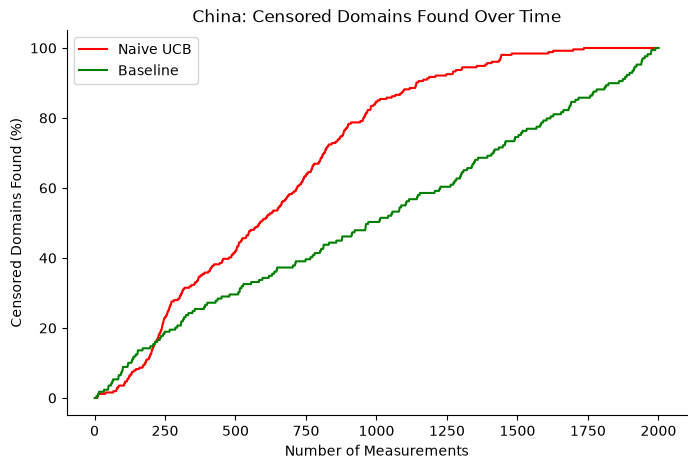

In [65]:
files = [
    f"{DATA_DIR}/exp1/China.csv",
    f"{DATA_DIR}/baseline/China.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("China: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

2


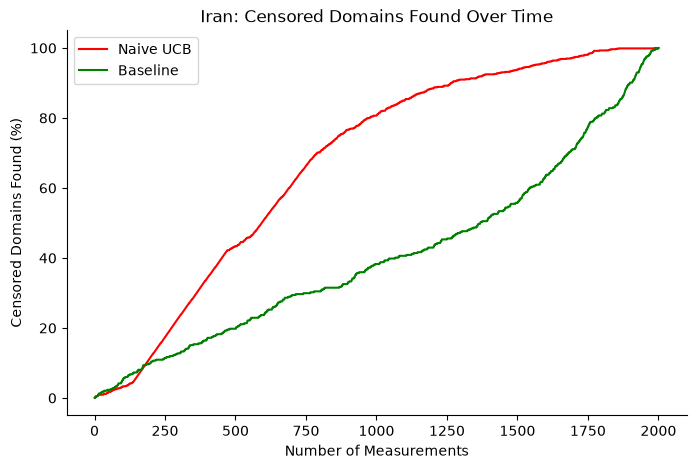

In [64]:
files = [
    f"{DATA_DIR}/exp1/Iran.csv",
    f"{DATA_DIR}/baseline/Iran.csv"
]

runs, times, names, colors, lines = get_over_time_compare_data(files) 
print(len(runs))
# = list(map(load_run, files)
# times = list(map(lambda df: df["time"], runs))
# names = list(map(get_exeriment_name, files))

# runs = list(map(convert_to_percentage, map(cumulative_found, runs)))

# # Denominator: all censored domains found by EITHER run, so both curves
# # share one scale. Change this line if you want a different definition.
# total_censored = max(exp_found[-1], base_found[-1])

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

# ax.plot(exp["time"], 100 * exp_found / total_censored, label="exp6")
# ax.plot(base["time"], 100 * base_found / total_censored, label="baseline")
# ax.plot(exp["time"], 100 * exp_found / exp_found[-1], label="exp6")
# ax.plot(base["time"], 100 * base_found / base_found[-1], label="baseline")
ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Iran: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

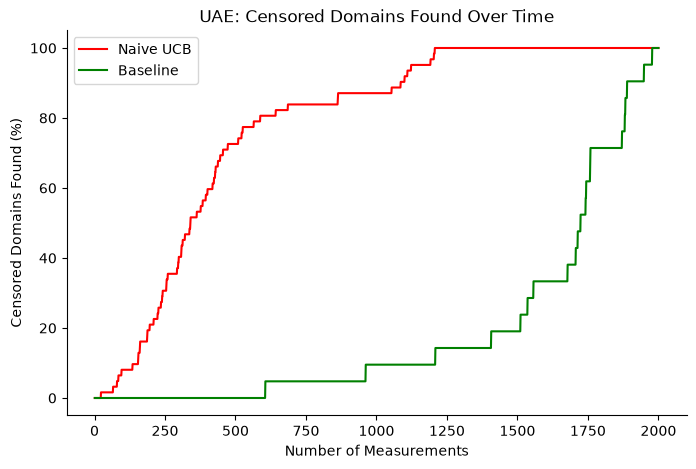

In [69]:
files = [
    f"{DATA_DIR}/exp1/United_Arab_Emirates.csv",
    f"{DATA_DIR}/baseline/United_Arab_Emirates.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("UAE: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

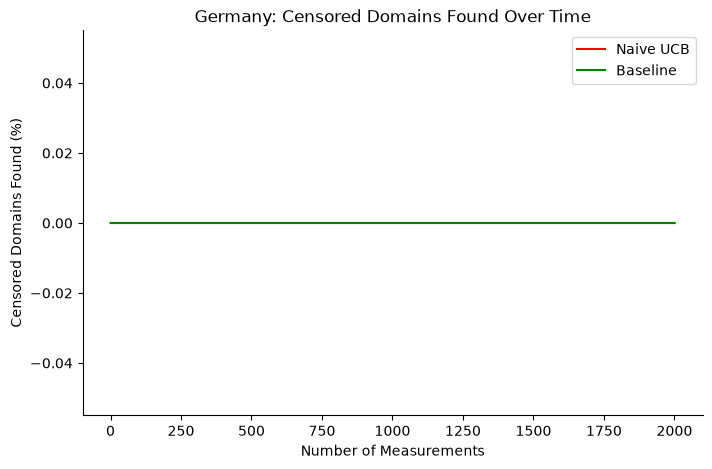

In [66]:
files = [
    f"{DATA_DIR}/exp1/Germany.csv",
    f"{DATA_DIR}/baseline/Germany.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Germany: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

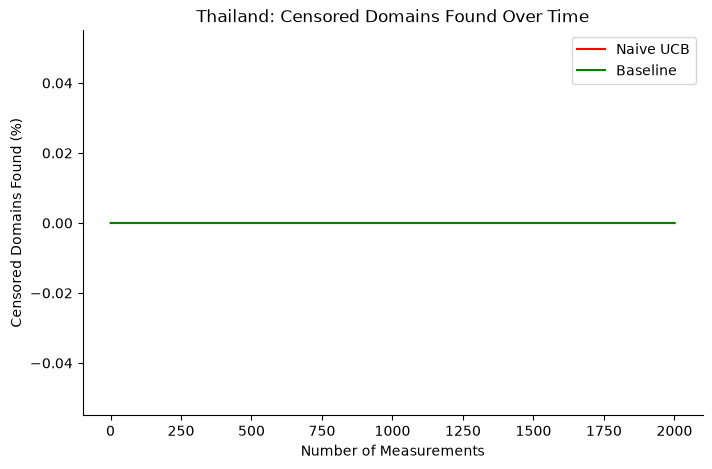

In [67]:
files = [
    f"{DATA_DIR}/exp1/Thailand.csv",
    f"{DATA_DIR}/baseline/Thailand.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Thailand: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

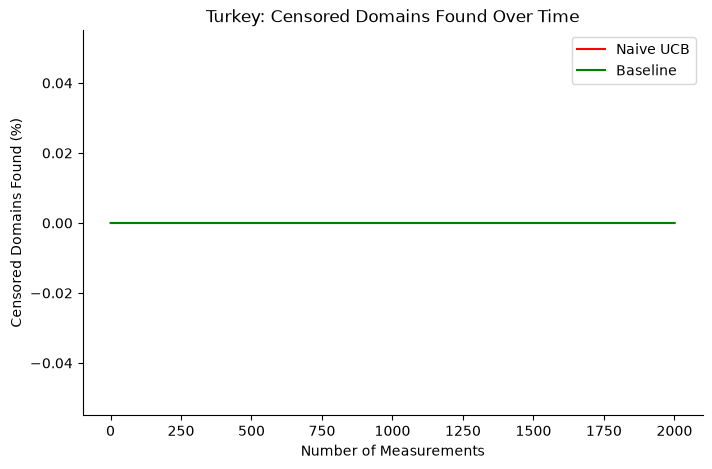

In [68]:
files = [
    f"{DATA_DIR}/exp1/Turkey.csv",
    f"{DATA_DIR}/baseline/Turkey.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Turkey: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

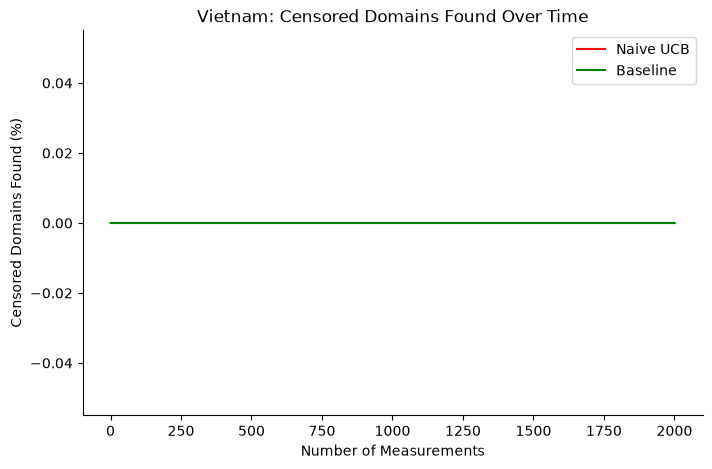

In [70]:
files = [
    f"{DATA_DIR}/exp1/Vietnam.csv",
    f"{DATA_DIR}/baseline/Vietnam.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Vietnam: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

### Policy comparison

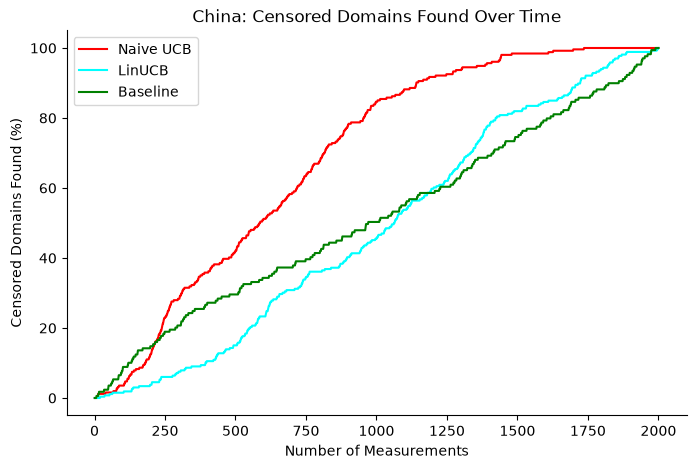

In [83]:
files = [
    f"{DATA_DIR}/exp1/China.csv",
    # f"{DATA_DIR}/exp2/China.csv",
    f"{DATA_DIR}/exp3/China.csv",
    # f"{DATA_DIR}/exp4/China.csv",
    f"{DATA_DIR}/baseline/China.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("China: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

3


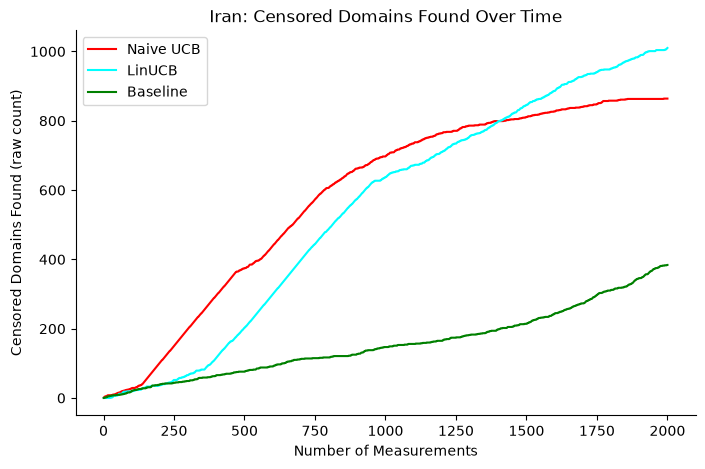

In [89]:
files = [
    f"{DATA_DIR}/exp1/Iran.csv",
    # f"{DATA_DIR}/exp2/Iran.csv",
    f"{DATA_DIR}/exp3/Iran.csv",
    # f"{DATA_DIR}/exp4/Iran.csv",
    f"{DATA_DIR}/baseline/Iran.csv"
]

runs, times, names, colors, lines = get_over_time_compare_data(files) 
print(len(runs))
# = list(map(load_run, files)
# times = list(map(lambda df: df["time"], runs))
# names = list(map(get_exeriment_name, files))

# runs = list(map(convert_to_percentage, map(cumulative_found, runs)))

# # Denominator: all censored domains found by EITHER run, so both curves
# # share one scale. Change this line if you want a different definition.
# total_censored = max(exp_found[-1], base_found[-1])

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

# ax.plot(exp["time"], 100 * exp_found / total_censored, label="exp6")
# ax.plot(base["time"], 100 * base_found / total_censored, label="baseline")
# ax.plot(exp["time"], 100 * exp_found / exp_found[-1], label="exp6")
# ax.plot(base["time"], 100 * base_found / base_found[-1], label="baseline")
ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Iran: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

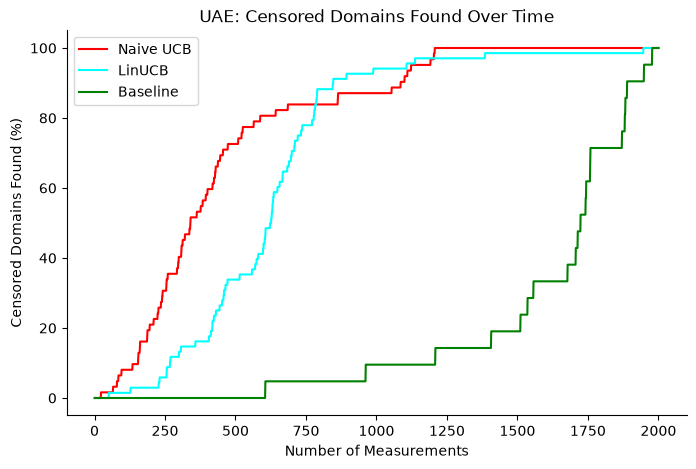

In [85]:
files = [
    f"{DATA_DIR}/exp1/United_Arab_Emirates.csv",
    # f"{DATA_DIR}/exp2/United_Arab_Emirates.csv",
    f"{DATA_DIR}/exp3/United_Arab_Emirates.csv",
    # f"{DATA_DIR}/exp4/United_Arab_Emirates.csv",
    f"{DATA_DIR}/baseline/United_Arab_Emirates.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("UAE: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

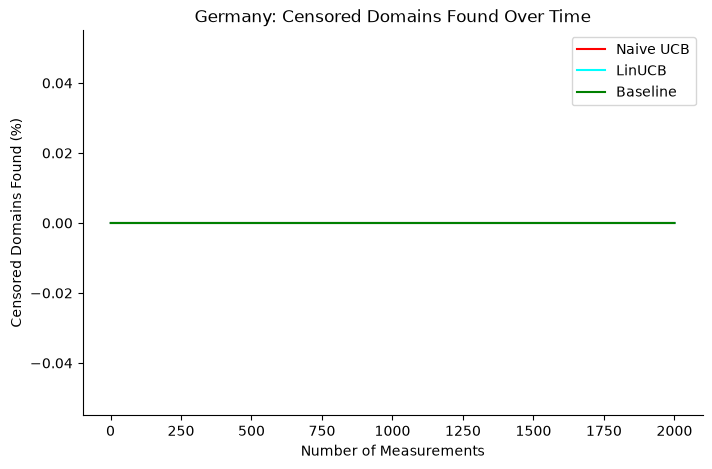

In [86]:
files = [
    f"{DATA_DIR}/exp1/Germany.csv",
    # f"{DATA_DIR}/exp2/Germany.csv",
    f"{DATA_DIR}/exp3/Germany.csv",
    # f"{DATA_DIR}/exp4/Germany.csv",
    f"{DATA_DIR}/baseline/Germany.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Germany: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

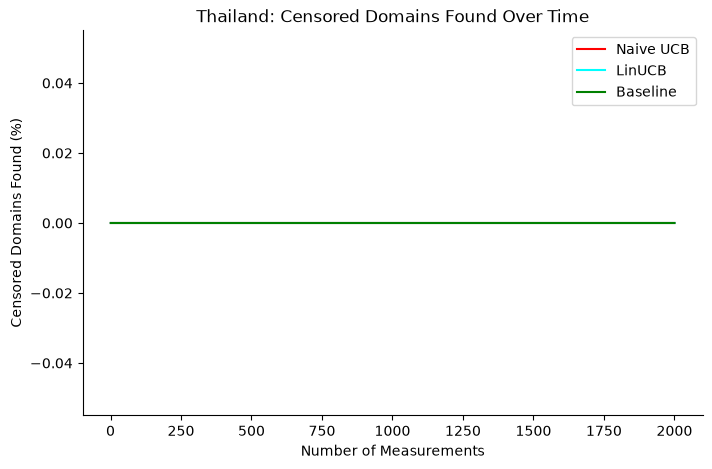

In [77]:
files = [
    f"{DATA_DIR}/exp1/Thailand.csv",
    # f"{DATA_DIR}/exp2/Thailand.csv",
    f"{DATA_DIR}/exp3/Thailand.csv",
    # f"{DATA_DIR}/exp4/Thailand.csv",
    f"{DATA_DIR}/baseline/Thailand.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Thailand: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

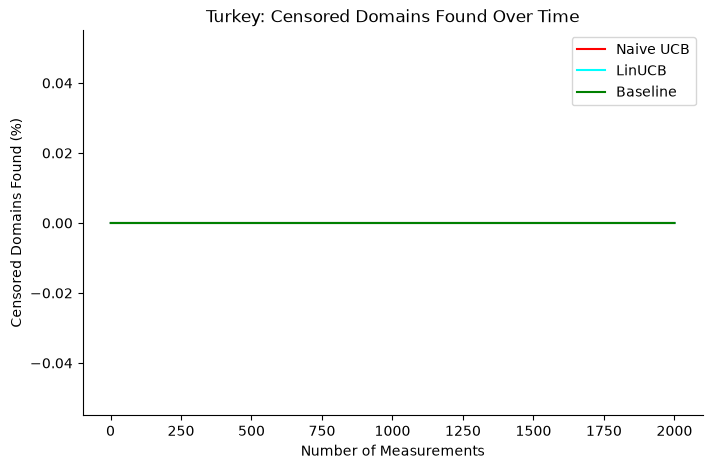

In [78]:
files = [
    f"{DATA_DIR}/exp1/Turkey.csv",
    # f"{DATA_DIR}/exp2/Turkey.csv",
    f"{DATA_DIR}/exp3/Turkey.csv",
    # f"{DATA_DIR}/exp4/Turkey.csv",
    f"{DATA_DIR}/baseline/Turkey.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Turkey: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

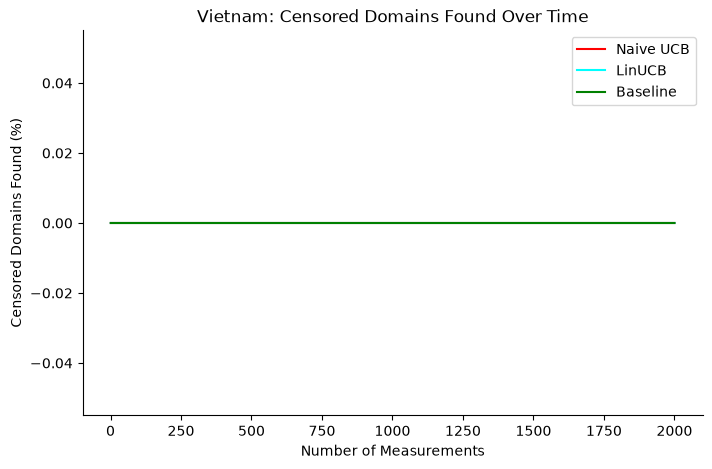

In [79]:
files = [
    f"{DATA_DIR}/exp1/Vietnam.csv",
    f"{DATA_DIR}/exp2/Vietnam.csv",
    f"{DATA_DIR}/exp3/Vietnam.csv",
    f"{DATA_DIR}/exp4/Vietnam.csv",
    f"{DATA_DIR}/baseline/Vietnam.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Vietnam: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

### Reward comparison

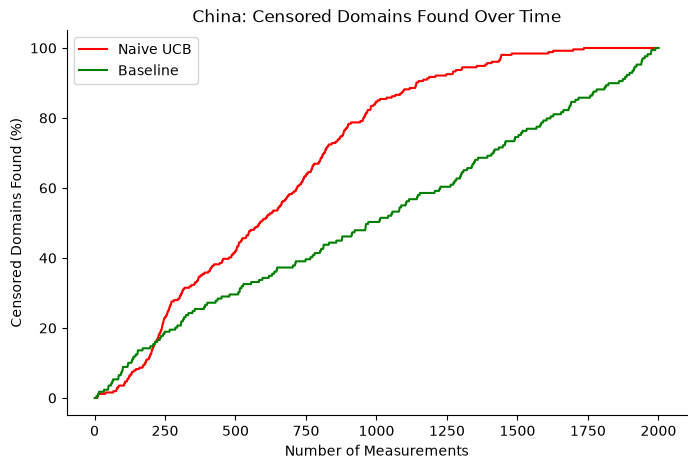

In [65]:
files = [
    # f"{DATA_DIR}/exp5/China.csv",
    f"{DATA_DIR}/exp6/China.csv",
    # f"{DATA_DIR}/exp7/China.csv",
    f"{DATA_DIR}/baseline/China.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("China: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

2


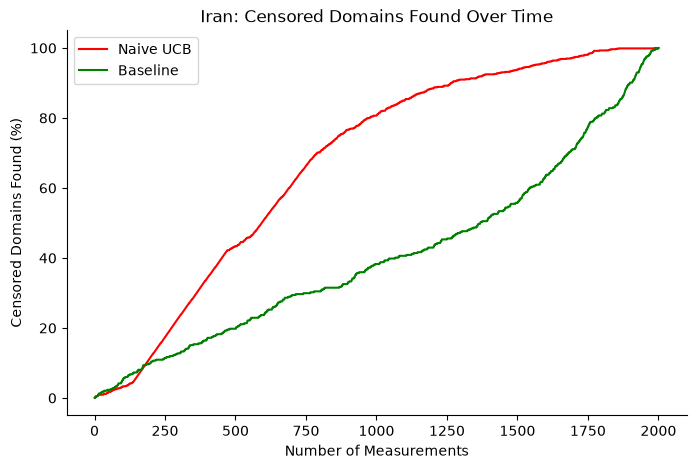

In [64]:
files = [
    # f"{DATA_DIR}/exp5/Iran.csv",
    f"{DATA_DIR}/exp6/Iran.csv",
    # f"{DATA_DIR}/exp7/Iran.csv",
    f"{DATA_DIR}/baseline/Iran.csv"
]

runs, times, names, colors, lines = get_over_time_compare_data(files) 
print(len(runs))
# = list(map(load_run, files)
# times = list(map(lambda df: df["time"], runs))
# names = list(map(get_exeriment_name, files))

# runs = list(map(convert_to_percentage, map(cumulative_found, runs)))

# # Denominator: all censored domains found by EITHER run, so both curves
# # share one scale. Change this line if you want a different definition.
# total_censored = max(exp_found[-1], base_found[-1])

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

# ax.plot(exp["time"], 100 * exp_found / total_censored, label="exp6")
# ax.plot(base["time"], 100 * base_found / total_censored, label="baseline")
# ax.plot(exp["time"], 100 * exp_found / exp_found[-1], label="exp6")
# ax.plot(base["time"], 100 * base_found / base_found[-1], label="baseline")
ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Iran: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

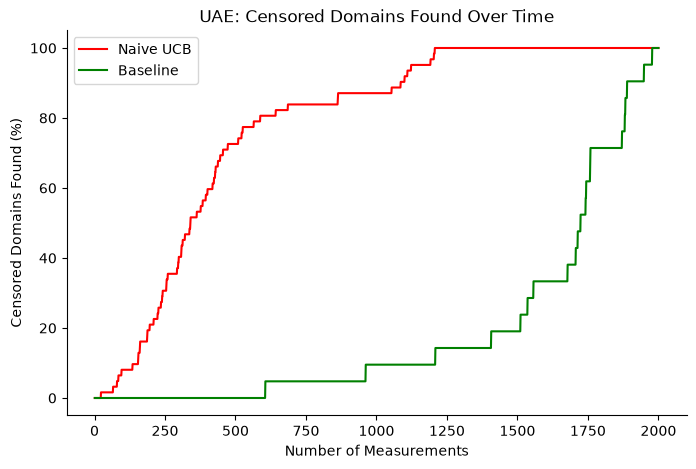

In [69]:
files = [
    # f"{DATA_DIR}/exp5/United_Arab_Emirates.csv",
    f"{DATA_DIR}/exp6/United_Arab_Emirates.csv",
    # f"{DATA_DIR}/exp7/United_Arab_Emirates.csv",
    f"{DATA_DIR}/baseline/United_Arab_Emirates.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("UAE: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

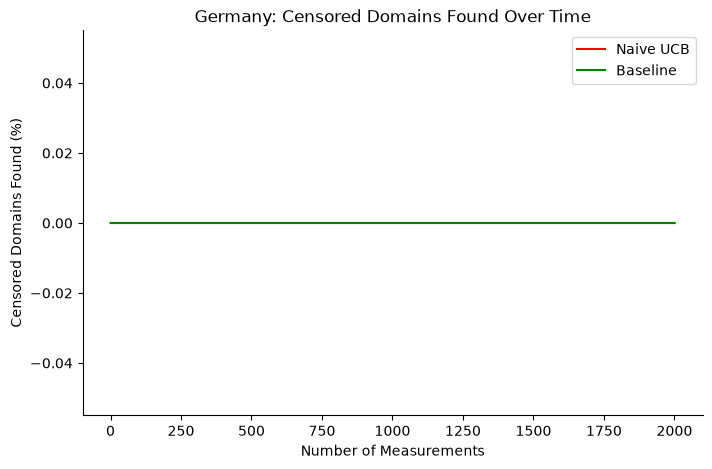

In [66]:
files = [
    # f"{DATA_DIR}/exp5/Germany.csv",
    f"{DATA_DIR}/exp6/Germany.csv",
    # f"{DATA_DIR}/exp7/Germany.csv",
    f"{DATA_DIR}/baseline/Germany.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Germany: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

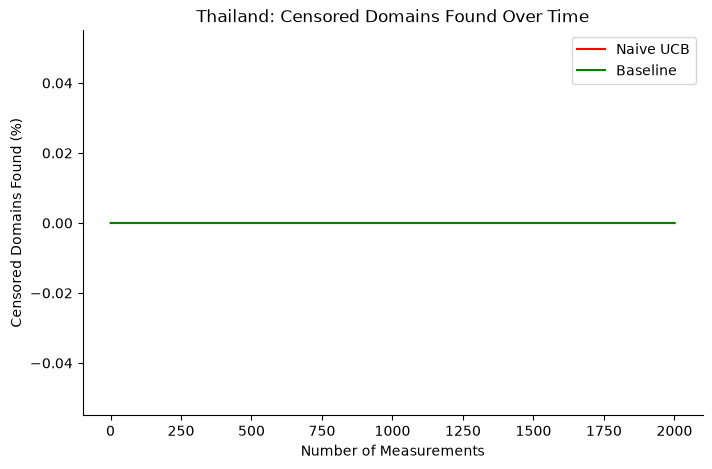

In [67]:
files = [
    # f"{DATA_DIR}/exp5/Thailand.csv",
    f"{DATA_DIR}/exp6/Thailand.csv",
    # f"{DATA_DIR}/exp7/Thailand.csv",
    f"{DATA_DIR}/baseline/Thailand.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Thailand: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

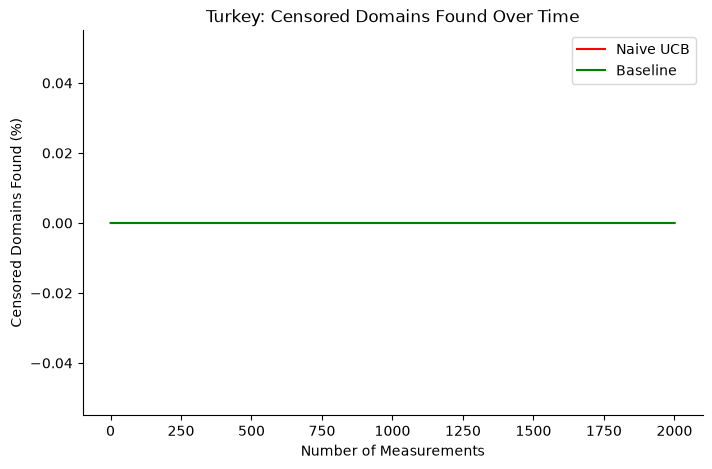

In [68]:
files = [
    # f"{DATA_DIR}/exp5/Turkey.csv",
    f"{DATA_DIR}/exp6/Turkey.csv",
    # f"{DATA_DIR}/exp7/Turkey.csv",
    f"{DATA_DIR}/baseline/Turkey.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Turkey: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

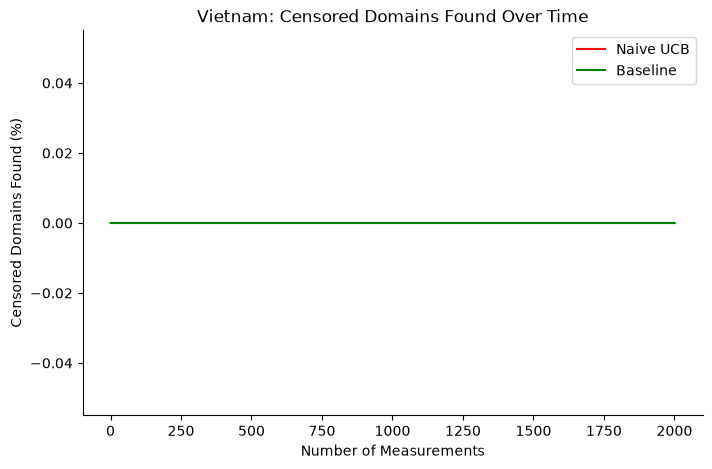

In [70]:
files = [
    # f"{DATA_DIR}/exp5/Vietnam.csv",
    f"{DATA_DIR}/exp6/Vietnam.csv",
    # f"{DATA_DIR}/exp7/Vietnam.csv",
    f"{DATA_DIR}/baseline/Vietnam.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Vietnam: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

### All (sanity check)

## Box-whisker plot of arm pulls

In [36]:
from matplotlib.lines import Line2D

In [37]:
min_domains = 100   # category must have at least this many distinct domains
n_each = 5          # how many to take from the top and from the bottom

stats = exp.groupby("category").agg(
    domains=("targets", "nunique"),
    avg_reward=("rewards", "mean"),
)
stats = stats[stats["domains"] >= min_domains]
stats = stats.sort_values("avg_reward", ascending=False)
print(stats)  # worth a look before plotting

                      domains  avg_reward
category                                 
Pornography               329    0.926322
Social Networks           239    0.797741
Personal Blogs            114    0.286053
Ecommerce                 421    0.137696
Advertisements            132    0.125606
Information Security      103    0.019417


In [38]:
top = list(stats.index[:n_each])
bottom = list(stats.index[-n_each:])

# dict.fromkeys drops repeats but keeps the order
selected = list(dict.fromkeys(top + bottom))

In [39]:
exp_sub = {cat: exp[exp["category"] == cat] for cat in selected}
base_sub = {cat: base[base["category"] == cat] for cat in selected}

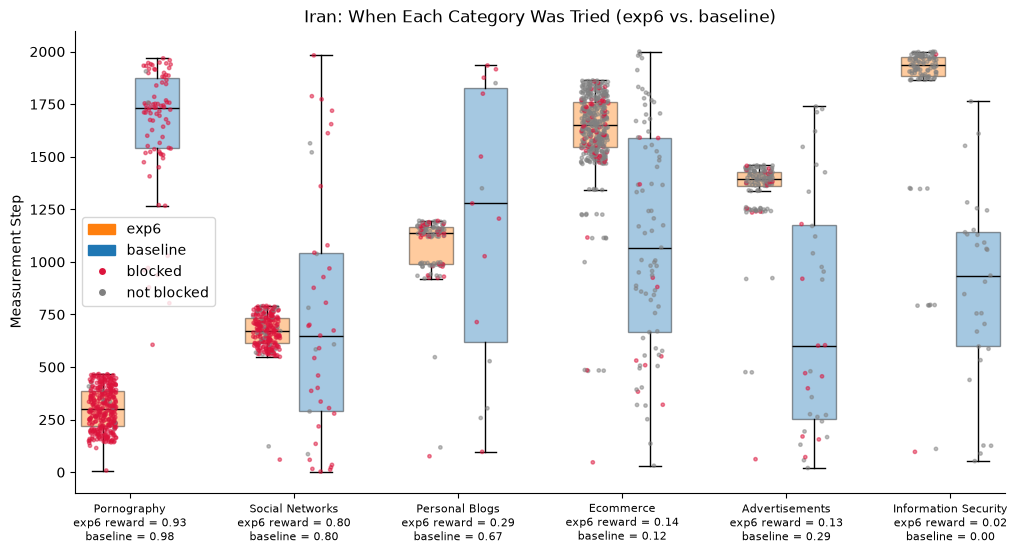

In [41]:
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(12, 6))

for i, cat in enumerate(selected):
    # exp6 box at x = 3*i, baseline box right next to it at 3*i + 1
    for offset, subs, color in [(0, exp_sub, "tab:orange"),
                                (1, base_sub, "tab:blue")]:
        data = subs[cat]["time"].to_numpy()
        bp = ax.boxplot([data], positions=[3 * i + offset], widths=0.8,
                        patch_artist=True, showfliers=False,
                        medianprops={"color": "black"})
        bp["boxes"][0].set_facecolor(color)
        bp["boxes"][0].set_alpha(0.4)   # make the box semi-transparent

rng = np.random.default_rng(0)  # fixed seed -> same jitter every run

for i, cat in enumerate(selected):
    for offset, subs in [(0, exp_sub), (1, base_sub)]:
        pts = subs[cat]
        # spread points sideways around the box center (box half-width is 0.4)
        x = 3 * i + offset + rng.uniform(-0.25, 0.25, size=len(pts))
        colors = np.where(pts["is_blocked"] == 1, "crimson", "gray")
        ax.scatter(x, pts["time"], c=colors, s=6, alpha=0.5, zorder=3)

labels = []
for cat in selected:
    e = exp_sub[cat]["rewards"].mean()
    b = base_sub[cat]["rewards"].mean()
    labels.append(f"{cat}\nexp6 reward = {e:.2f}\nbaseline = {b:.2f}")

ax.set_xticks([3 * i + 0.5 for i in range(len(selected))])
ax.set_xticklabels(labels, fontsize=8)

ax.set_ylabel("Measurement Step")
ax.set_title("Iran: When Each Category Was Tried (exp6 vs. baseline)")
ax.legend(handles=[
    Patch(color="tab:orange", label="exp6"),
    Patch(color="tab:blue", label="baseline"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="crimson", label="blocked"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="gray", label="not blocked"),
])
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Arm selection over time

In [16]:
NUM_ARMS_TO_COMPARE = 10

top_arms = exp["category"].value_counts().head(NUM_ARMS_TO_COMPARE).index
print(list(top_arms))  # check which categories were picked

['Ecommerce', 'Pornography', 'Social Networks', 'Advertisements', 'Personal Blogs', 'Information Security', 'Auctions & Marketplaces', 'Movies', 'Television', 'No Content']


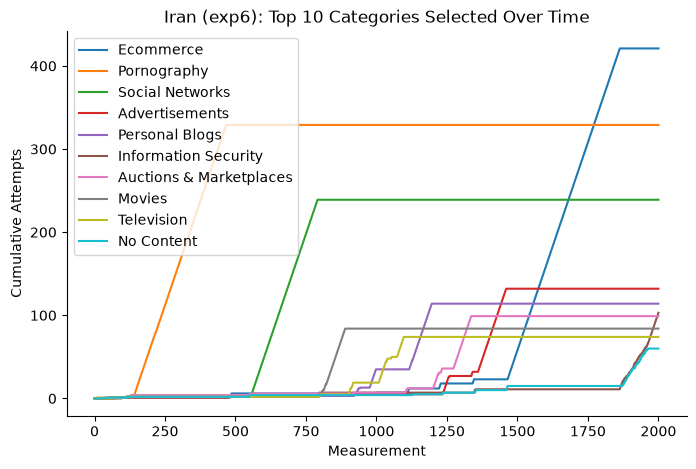

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
for cat in top_arms:
    # True/False per measurement -> running total of times this arm was picked
    ax.plot(exp["time"], (exp["category"] == cat).cumsum(), label=cat)

ax.set_xlabel("Measurement")
ax.set_ylabel("Cumulative Attempts")
ax.set_title(f"Iran (exp6): Top {NUM_ARMS_TO_COMPARE} Categories Selected Over Time")
ax.spines[["top", "right"]].set_visible(False)
ax.legend()
plt.show()